In [1]:
# Make the project importable whether this runs from notebooks/ or the repo root.
import pathlib
import sys

_root = next(
    p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
    if (p / "src" / "__init__.py").exists()
)
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

# 02 · Point-in-Time From Scratch

**The leak, measured.** This is the single most important feature-store concept, made
concrete. We build the same training set two ways:

- **Naive** — join each customer's *latest* feature value onto every historical label.
- **Honest** — a point-in-time `merge_asof` join that gives each label only the value known
  *at or before* its event time.

We train a model on each, then score them offline and on a **true-future holdout** the models
never saw. The naive model's offline score is inflated; the future erases the difference.

In [2]:
from src.artifacts import apply_style, save_figure, save_json, BLUE, ORANGE, MUTED
from src.config import settings, ENTITY_COL, EVENT_TS_COL, FEATURE_COL, LABEL_COL
from src.datasets.events import load
from src.ministore.store import FeatureStore
from src.evaluation.leakage import run_leakage_experiment
import matplotlib.pyplot as plt
import numpy as np

apply_style()
ds = load(settings)
store = FeatureStore(ds.feature_history)
store.materialize(ds.feature_history[EVENT_TS_COL].max(), [FEATURE_COL])

,customer_id,txn_count_30d,event_timestamp
0,0,27,2024-06-28
1,1,29,2024-06-28
2,2,16,2024-06-28
3,3,5,2024-06-28
4,4,6,2024-06-28
...,...,...,...
1995,1995,18,2024-06-28
1996,1996,8,2024-06-28
1997,1997,21,2024-06-28
1998,1998,4,2024-06-28


## Two training sets, one request

Both start from the same request rows `(customer_id, event_timestamp, label)`. The honest set
uses the offline store's point-in-time join; the naive set uses the online store's latest value.

In [3]:
requests = ds.events[[ENTITY_COL, EVENT_TS_COL, LABEL_COL]].copy()

# Honest: point-in-time join (value known at/before the event time).
honest = store.get_historical_features(
    requests[[ENTITY_COL, EVENT_TS_COL]], [FEATURE_COL], keep_feature_timestamp=True
)
# Naive: the latest value per customer, joined onto every label.
naive_latest = store.get_online_features(requests[ENTITY_COL].tolist(), [FEATURE_COL])

compare = requests[[ENTITY_COL, EVENT_TS_COL, LABEL_COL]].copy()
compare["honest_point_in_time"] = honest[FEATURE_COL].to_numpy()
compare["naive_latest"] = naive_latest[FEATURE_COL].to_numpy()
compare.head(8)

,customer_id,event_timestamp,label,honest_point_in_time,naive_latest
0,0,2024-04-23,1,10,27
1,1,2024-03-11,1,21,29
2,2,2024-06-07,0,14,16
3,3,2024-04-14,0,18,5
4,4,2024-04-04,0,21,6
5,5,2024-06-12,1,8,39
6,6,2024-04-09,0,22,2
7,7,2024-05-15,1,17,31


### The invariant: the honest join never reads the future

The matched feature timestamp is always **at or before** the event time. We assert it — this
is the rule the whole category exists to enforce.

In [4]:
never_after = bool((honest["_feature_timestamp"] <= honest[EVENT_TS_COL]).all())
assert never_after, "point-in-time join used a value after the event time!"
print("point-in-time join never used a value after the event time:", never_after)

point-in-time join never used a value after the event time: True


## Train on each, score offline and on the true future

`run_leakage_experiment` trains a logistic model on each training set, scores both on a
held-out slice of the same era (**offline**), then scores both on a genuine **future**
holdout — where the only feature available is the point-in-time value, because the future
has not happened yet at prediction time.

In [5]:
result = run_leakage_experiment(ds, settings)
print(f"naive  offline AUC : {result.naive_offline_auc:.3f}")
print(f"honest offline AUC : {result.honest_offline_auc:.3f}")
print(f"naive  future  AUC : {result.naive_future_auc:.3f}")
print(f"honest future  AUC : {result.honest_future_auc:.3f}")
print(f"inflation (naive-honest, offline): {result.inflation:.3f}")
print(f"collapse  (naive offline-future): {result.collapse:.3f}")

naive  offline AUC : 0.864
honest offline AUC : 0.724
naive  future  AUC : 0.712
honest future  AUC : 0.712
inflation (naive-honest, offline): 0.141
collapse  (naive offline-future): 0.152


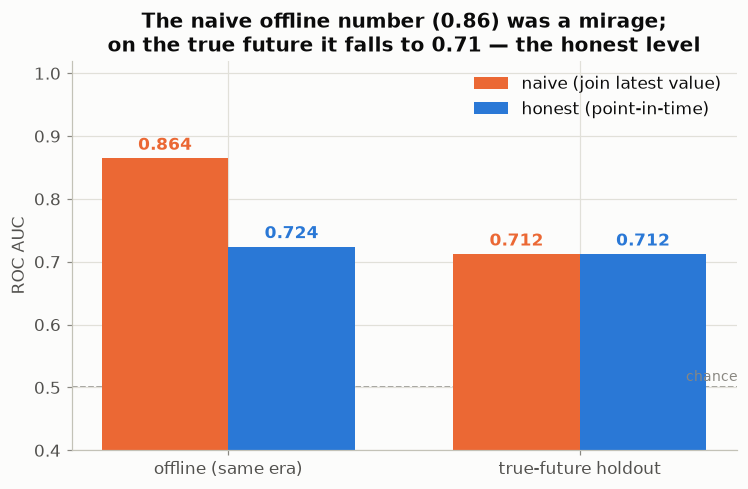

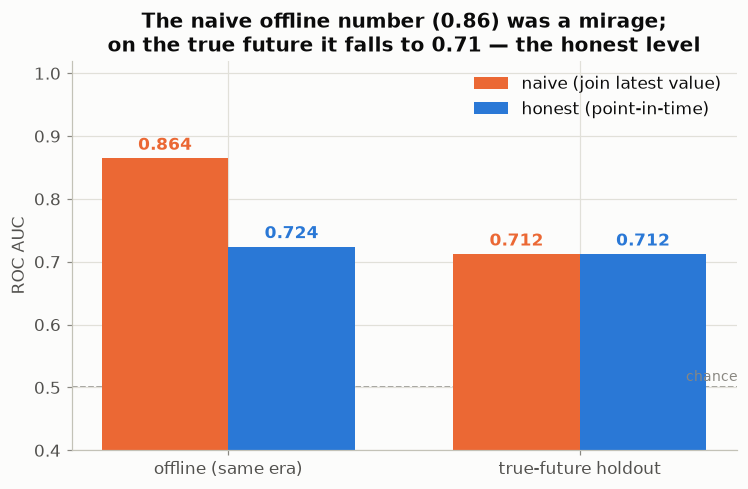

In [6]:
groups = ["offline (same era)", "true-future holdout"]
naive_vals = [result.naive_offline_auc, result.naive_future_auc]
honest_vals = [result.honest_offline_auc, result.honest_future_auc]
x = np.arange(len(groups))
width = 0.36

fig, ax = plt.subplots(figsize=(7.8, 4.6))
b1 = ax.bar(x - width / 2, naive_vals, width, color=ORANGE, label="naive (join latest value)")
b2 = ax.bar(x + width / 2, honest_vals, width, color=BLUE, label="honest (point-in-time)")
ax.axhline(0.5, color=MUTED, ls="--", lw=1, zorder=0)
ax.text(x[-1] + 0.45, 0.505, "chance", color=MUTED, fontsize=9, va="bottom", ha="right")
ax.bar_label(b1, fmt="%.3f", padding=3, fontweight="bold", color=ORANGE)
ax.bar_label(b2, fmt="%.3f", padding=3, fontweight="bold", color=BLUE)
ax.set_xticks(x, groups)
ax.set_ylim(0.4, 1.02)
ax.set_ylabel("ROC AUC")
ax.set_title(
    f"The naive offline number ({result.naive_offline_auc:.2f}) was a mirage;\n"
    f"on the true future it falls to {result.naive_future_auc:.2f} — the honest level"
)
ax.legend(frameon=False, loc="upper right")
save_figure(fig, "02_leakage_auc_bars")
fig

## Why it leaks: the latest value encodes the outcome

Split the two features by the label. The **naive latest** value separates the classes far more
than the **honest point-in-time** value does — because post-event behaviour (which depends on
the outcome) has leaked into it. That extra separation is exactly the inflation above.

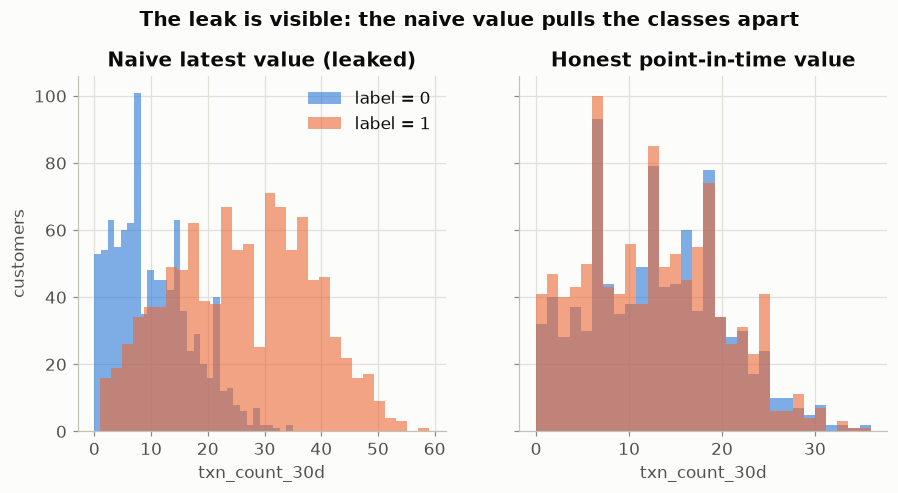

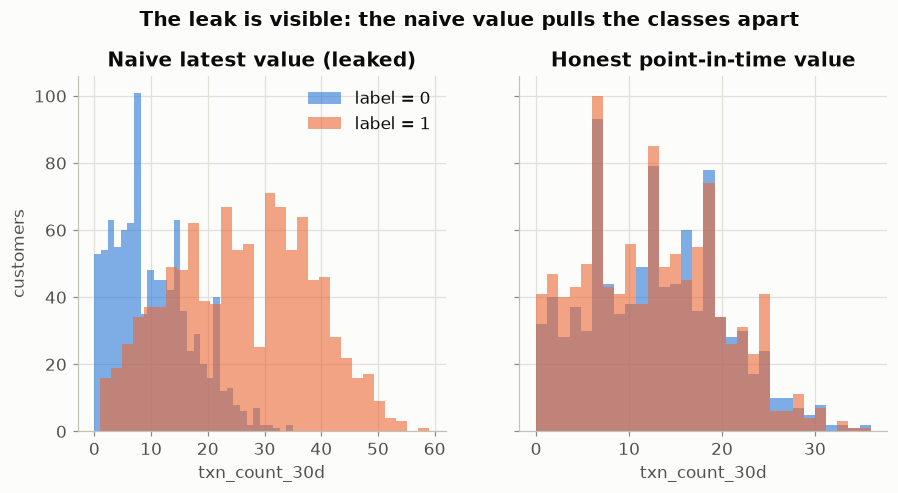

In [7]:
merged = compare.merge(ds.events[[ENTITY_COL, LABEL_COL]], on=ENTITY_COL, suffixes=("", "_y"))
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.2), sharey=True)
for ax, col, title in [
    (axes[0], "naive_latest", "Naive latest value (leaked)"),
    (axes[1], "honest_point_in_time", "Honest point-in-time value"),
]:
    for label, color in [(0, BLUE), (1, ORANGE)]:
        vals = merged.loc[merged[LABEL_COL] == label, col]
        ax.hist(vals, bins=30, color=color, alpha=0.6, label=f"label = {label}")
    ax.set_title(title)
    ax.set_xlabel("txn_count_30d")
axes[0].set_ylabel("customers")
axes[0].legend(frameon=False)
fig.suptitle("The leak is visible: the naive value pulls the classes apart", y=1.02,
             fontsize=13, fontweight="bold")
save_figure(fig, "02_feature_by_label")
fig

In [8]:
payload = {
    "auc": {
        "naive_offline": result.naive_offline_auc,
        "honest_offline": result.honest_offline_auc,
        "naive_future": result.naive_future_auc,
        "honest_future": result.honest_future_auc,
    },
    "inflation": result.inflation,
    "collapse": result.collapse,
    "point_in_time_never_uses_future_value": never_after,
    "takeaway": (
        "The naive join inflated offline AUC by leaking post-event behaviour; on a true-future "
        "holdout the inflation vanished and the naive model fell to the honest model's level. "
        "The gap was leakage, not skill."
    ),
}
print(save_json(payload, "02_leakage_results"))
payload["auc"]

/workspaces/feature_store_101/outputs/json/02_leakage_results.json


{'naive_offline': 0.8644822516278093,
 'honest_offline': 0.7238920394875026,
 'naive_future': 0.7121107313368056,
 'honest_future': 0.7121107313368056}

## Next

**[03 · Build a Store in 100 Lines](03_build_a_store_in_100_lines.ipynb)** — assemble the
registry, offline store, online store, and materialize step into the two methods every
feature store exposes.